You need to run each pip install in a separate block for it to work (not sure why)

In [1]:
#pip install pyblp
#pip install pandas
#pip install pyRVtest
#pip install matplotlib
#pip install Jinja2

In [2]:
import pyblp
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pyRVtest
from IPython.display import display

import io
import re
from contextlib import redirect_stdout


pyblp.options.digits = 5
pyblp.options.verbose = False
pyblp.__version__

'1.1.2'

In [3]:
#choose the dataset you want
product_data = pd.read_csv("LETF_product_month_level_v4_patched.csv")

# keep only bear or bull
product_data = product_data[product_data["market_m_bull_bear"] == "Bull"]

# need to create unique market id
product_data["market_ids"] = product_data.groupby(["month_t", "market_m_bull_bear"]).ngroup()+1

display(product_data[["month_t", "market_m_bull_bear", "market_ids"]].drop_duplicates().sort_values("market_ids").head())

# create some variable needed for estimation
product_data["log_product_fund_age"] = np.log(product_data["product_fund_age"])
product_data["product_tracking_err"] = abs(product_data["product_tracking_err"])

# additional filters
product_data = product_data.dropna(subset=['BLP_IV_hausman_mgmt_fee'])

# create the cluster_ids used for cluster SE throughout
product_data['clustering_ids'] = product_data.market_ids

display(product_data["market_ids"].describe())


,month_t,market_m_bull_bear,market_ids
2807,2007.000000,Bull,1
2808,2007.083333,Bull,2
414,2007.166667,Bull,3
416,2007.250000,Bull,4
418,2007.333333,Bull,5


count    26935.000000
mean       118.424726
std         56.842606
min          1.000000
25%         71.000000
50%        120.000000
75%        167.000000
max        213.000000
Name: market_ids, dtype: float64

In [4]:
# need to rename to prices and shares  and IV for using built in package below
product_data = product_data.rename(columns={
    'product_exp_ratio': 'prices',
    'market_share_m_bull_bear': 'shares_old',
    'BLP_IV_hausman_exp_ratio': 'demand_instruments0',
    #'IV2_exp_ratio_vw': 'demand_instruments1', # This is not needed for logit which only requires one IV for the price
    'firm_f': 'firm_ids',
    'product_ticker': 'product_ids',
})

# compute the market shares (PyBLP needs they sum up to less than 1!)
product_data["shares"] = (
    #product_data["product_mtna"] / product_data.groupby("market_ids")["product_mtna"].transform("sum")
    product_data["product_mtna"] / product_data["market_share_m_bull_bear_denom"]
)

# outside option filters and defining firm_ids
product_data = product_data.loc[product_data['shares'] >= 0.0001]
product_data = product_data.loc[product_data['month_t'] >=2010]
product_data = product_data[product_data['firm_ids'].isin(['ProShares','Direxion','ProFunds'])]


# add together the residualized index returns across the three horizons 
product_data["rotator"] = (
    product_data["Conduct_IV_neg_vw_ind_resid_1m"] + product_data["Conduct_IV_neg_vw_ind_resid_2to5m"] + product_data["Conduct_IV_neg_vw_ind_resid_6to12m"]
)

display(product_data["prices"].describe())
display(product_data["shares_old"].describe())
display(product_data["shares"].describe())
display(product_data["product_mtna"].describe())
display(product_data["firm_ids"].describe())
display(product_data["product_ids"].describe())

display(product_data.info())
display(product_data.head(10))

count    15401.000000
mean         1.336491
std          0.566721
min          0.040000
25%          0.950000
50%          0.950000
75%          1.710000
max          2.920000
Name: prices, dtype: float64

count    15401.000000
mean         0.010806
std          0.026423
min          0.000100
25%          0.000517
50%          0.001608
75%          0.007283
max          0.303106
Name: shares_old, dtype: float64

count    15401.000000
mean         0.010806
std          0.026423
min          0.000100
25%          0.000517
50%          0.001608
75%          0.007283
max          0.303106
Name: shares, dtype: float64

count    15401.000000
mean       309.484920
std       1135.229874
min          1.000000
25%         11.300000
50%         34.600000
75%        163.300000
max      24666.600000
Name: product_mtna, dtype: float64

count        15401
unique           3
top       ProFunds
freq          5564
Name: firm_ids, dtype: object

count              15401
unique               146
top       UPRO US Equity
freq                 177
Name: product_ids, dtype: object

<class 'pandas.core.frame.DataFrame'>
Index: 15401 entries, 2 to 48274
Columns: 140 entries, market_m_index to rotator
dtypes: float64(116), int64(15), object(9)
memory usage: 16.6+ MB


None

,market_m_index,month_t,product_j,firm_ids,market_m_bull_bear,market_m_cluster,market_m_index_mret,product_fund_name,product_daily,product_leverage,...,FMAX_resid1,csent_index,csent_index_resid,csent_index_resid1,chg_VIX,chg_VIX_resid,market_ids,clustering_ids,shares,rotator
2,AAPL,2023.166667,100446,Direxion,Bull,197,0.118650,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,3.782691,62.0,62.493749,62.081951,-2.00,1.191402,195,195,0.000358,0.113479
5,AAPL,2023.250000,100446,Direxion,Bull,197,0.028988,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,-5.447587,63.7,63.783406,64.572340,-2.92,-2.140528,196,196,0.000392,0.063090
8,AAPL,2023.333333,100446,Direxion,Bull,197,0.046067,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,3.626101,59.0,59.112726,57.809769,2.16,3.398498,197,197,0.000433,0.033786
11,AAPL,2023.416667,100446,Direxion,Bull,197,0.094328,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,1.403441,64.2,64.537519,65.262418,-4.35,-1.797911,198,198,0.000554,0.038335
14,AAPL,2023.500000,100446,Direxion,Bull,197,0.012785,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,6.038689,71.5,71.546324,71.394183,0.04,0.383423,199,199,0.000584,0.045185
17,AAPL,2023.583333,100446,Direxion,Bull,197,-0.042386,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,-5.258952,69.4,69.258574,69.763642,-0.06,-1.194157,200,200,0.000679,0.086289
20,AAPL,2023.666667,100446,Direxion,Bull,197,-0.088677,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,-1.592889,67.8,67.566024,66.932222,3.95,1.544927,201,201,0.000706,0.015871
23,AAPL,2023.750000,100446,Direxion,Bull,197,-0.002568,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,-5.871562,63.8,63.796481,63.669464,0.37,0.300578,202,202,0.000686,0.030278
26,AAPL,2023.833333,100446,Direxion,Bull,197,0.113743,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,1.574279,61.3,61.381353,62.241691,-5.22,-2.183297,203,203,0.000566,0.067087
29,AAPL,2023.916667,100446,Direxion,Bull,197,0.013583,Direxion Shares ETF Trust: Direxion Daily AAPL...,1,1.5,...,9.665471,69.7,69.713961,69.761837,-0.47,-0.106840,204,204,0.000481,0.046672


In [5]:
# Compare share old (from CSV) and new (computed by me in python)
exact_match = (product_data["shares"] == product_data["shares_old"]).all()
close_match = np.allclose(product_data["shares"], product_data["shares_old"], rtol=1e-8, atol=1e-12)
abs_diff = (product_data["shares"] - product_data["shares_old"]).abs().max()

print("Exact equality:          ", exact_match)
print("All close (float-safe):  ", close_match)
print("Max absolute difference: ", abs_diff)

# Ad-hoc solution to make sure PyBLP run
#product_data["shares"] *= 0.5


Exact equality:           False
All close (float-safe):   True
Max absolute difference:  5.134781488891349e-16


In [6]:
# Prepare Logit with Demand Rotator
logit_formulation = pyblp.Formulation('prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')
logit_formulation


prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)]

In [7]:
# Show logit problem
logit_problem = pyblp.Problem(logit_formulation, product_data)
logit_problem

Dimensions:
 T     N     F    K1    MD    ED 
---  -----  ---  ----  ----  ----
177  15401   3    4     4     2  

Formulations:
     Column Indices:          0              1                     2                     3          
--------------------------  ------  --------------------  --------------------  --------------------
X1: Linear Characteristics  prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age

In [8]:
# Solve logit
logit_results = logit_problem.solve(se_type='clustered')
logit_results

Problem Results Summary:
GMM    Objective   Clipped  Weighting Matrix  Covariance Matrix
Step     Value     Shares   Condition Number  Condition Number 
----  -----------  -------  ----------------  -----------------
 2    +1.2581E-27     0       +1.2787E+03        +9.4917E+01   

Cumulative Statistics:
Computation   Objective 
   Time      Evaluations
-----------  -----------
 00:00:00         2     

Beta Estimates (Robust SEs Adjusted for 177 Clusters in Parentheses):
   prices      product_tracking_err  product_past_1yr_ret  log_product_fund_age
-------------  --------------------  --------------------  --------------------
 -3.7116E+00       -1.3755E+00           +2.5450E-01           +7.0644E-01     
(+3.2840E-01)     (+2.4729E-01)         (+3.5883E-02)         (+4.0441E-02)    

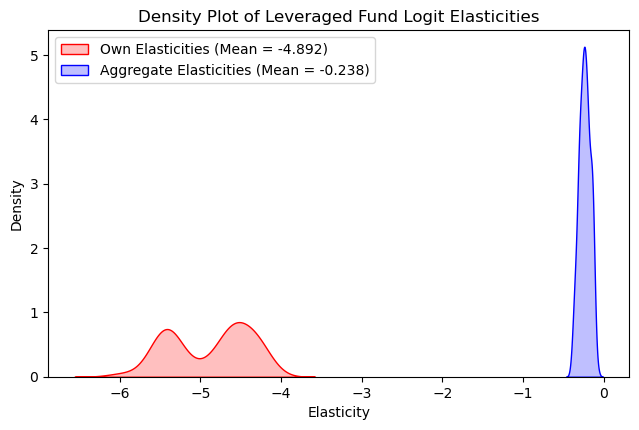

In [9]:
# compute elasticities, diversion ratio
logit_elasticities = logit_results.compute_elasticities()
logit_diversions = logit_results.compute_diversion_ratios()
logit_means = logit_results.extract_diagonal_means(logit_elasticities)
logit_aggregates = logit_results.compute_aggregate_elasticities(factor=0.1)

mean_own = logit_means.flatten().mean()
mean_agg = logit_aggregates.flatten().mean()

import matplotlib.pyplot as plt
import seaborn as sns

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(logit_means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(logit_aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Leveraged Fund Logit Elasticities")

# Save and show
plt.savefig("./logit_lasticities_density_LETF.pdf", format="pdf", bbox_inches="tight")
plt.show()


In [10]:
# Elasticities of the other variables
print(logit_results.extract_diagonal_means(logit_results.compute_elasticities(name='product_tracking_err')).flatten().mean())
print(logit_results.extract_diagonal_means(logit_results.compute_elasticities(name='product_past_1yr_ret')).flatten().mean())
print(logit_results.extract_diagonal_means(logit_results.compute_elasticities(name='log_product_fund_age')).flatten().mean())

-0.022829645265615425
0.05732503255951692
1.4944347339293533


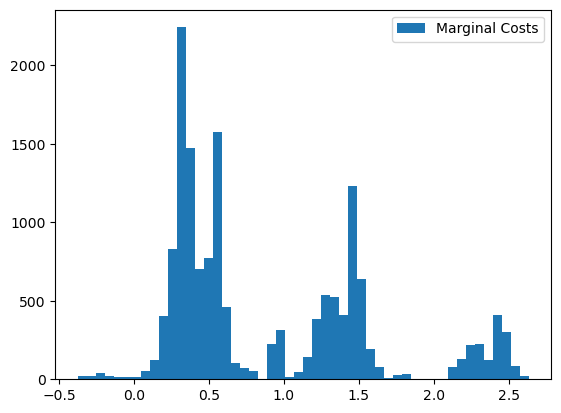

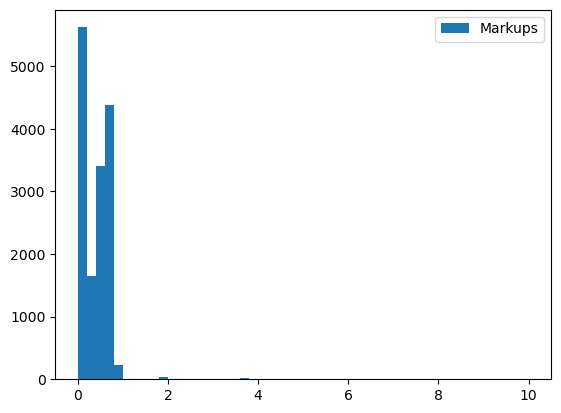

array([[0.5101311 ],
       [0.51620924],
       [0.51153139],
       ...,
       [0.38937721],
       [0.39518408],
       [0.40576814]], shape=(15401, 1))

array([[0.4630199 ],
       [0.45662185],
       [0.4615459 ],
       ...,
       [0.52514974],
       [0.51806819],
       [0.5051608 ]], shape=(15401, 1))

count    15401.000000
mean         0.896585
std          0.677269
min         -0.375385
25%          0.348020
50%          0.556714
75%          1.425182
max          2.633207
dtype: float64

count    15401.000000
mean         0.429411
std          0.427695
min          0.097127
25%          0.169350
50%          0.417155
75%          0.632417
max         10.384631
dtype: float64

In [11]:
# compute costs and markups

costs = logit_results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./logit_marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

markups = logit_results.compute_markups(costs=costs)
plt.hist(markups, bins=50, range=(0,10));
plt.legend(["Markups"]);
plt.savefig("./logit_markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

display(costs)
display(markups)

display(pd.Series(costs.ravel()).describe())
display(pd.Series(markups.ravel()).describe())


In [12]:
# BLP estimation: need more instruments
product_data = product_data.rename(columns={
    # This is too correlated with BLP_IV_hausman_exp_ratio (renamed as demand_instruments1 above for logit estimation)
    #'BLP_IV_hausman_op_cost': 'demand_instruments1',
    # This one seems to work since it has some nice independent variation
    'BLP_IV_rival_funds1': 'demand_instruments1'
    # This 
    #'BLP_IV_rival_funds4': 'demand_instruments2'
})

# Prepare BLP 
X1_formulation = pyblp.Formulation('0 + prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

(prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age + Absorb[C(product_ids)] + Absorb[C(market_ids)],
 prices)

In [13]:
mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

Configured to construct nodes and weights with Monte Carlo simulation with options {seed: 623543}.

In [14]:
mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

Dimensions:
 T     N     F     I      K1    K2    MD    ED 
---  -----  ---  ------  ----  ----  ----  ----
177  15401   3   531000   4     1     5     2  

Formulations:
       Column Indices:           0              1                     2                     3          
-----------------------------  ------  --------------------  --------------------  --------------------
 X1: Linear Characteristics    prices  product_tracking_err  product_past_1yr_ret  log_product_fund_age
X2: Nonlinear Characteristics  prices                                                                  

In [15]:
bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

Configured to optimize using the BFGS algorithm implemented in SciPy with analytic gradients and options {gtol: +1.0000E-07}.

In [16]:
# Solve BLP
results = mc_problem.solve(np.ones((1,1)), optimization=bfgs, se_type='clustered')
results

Problem Results Summary:
GMM    Objective    Gradient                 Clipped  Weighting Matrix  Covariance Matrix
Step     Value        Norm        Hessian    Shares   Condition Number  Condition Number 
----  -----------  -----------  -----------  -------  ----------------  -----------------
 2    +5.0375E+00  +9.4942E-08  +2.9383E+00     0       +2.9168E+04        +3.0492E+16   

Cumulative Statistics:
Computation  Optimizer  Optimization   Objective   Fixed Point  Contraction
   Time      Converged   Iterations   Evaluations  Iterations   Evaluations
-----------  ---------  ------------  -----------  -----------  -----------
 00:37:58       Yes          6            41         107744       329295   

Nonlinear Coefficient Estimates (Robust SEs Adjusted for 177 Clusters in Parentheses):
Sigma:     prices    
------  -------------
prices   +2.0836E+00 
        (+1.0209E-01)

Beta Estimates (Robust SEs Adjusted for 177 Clusters in Parentheses):
   prices      product_tracking_err  pro

In [17]:
# compute elasticities, diversion ratio, costs, and markups
elasticities = results.compute_elasticities()
diversions = results.compute_diversion_ratios()
costs = results.compute_costs()
markups = results.compute_markups(costs=costs)

In [18]:
means = results.extract_diagonal_means(elasticities)
aggregates = results.compute_aggregate_elasticities(factor=0.1)

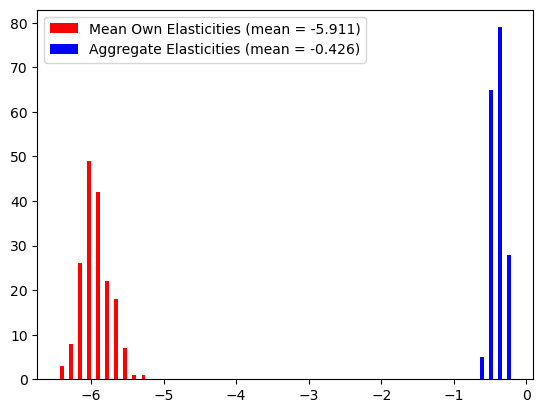

In [19]:
mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()

plt.hist(
    [means.flatten(), aggregates.flatten()], 
    color=['red', 'blue'], 
    bins=50
);
# --- legend with numbers embedded ---
plt.legend([
    f"Mean Own Elasticities (mean = {mean_own:.3f})",
    f"Aggregate Elasticities (mean = {mean_agg:.3f})"
])
plt.savefig("./elasticities_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [20]:
# Elasticities of the other variables
print(results.extract_diagonal_means(results.compute_elasticities(name='product_tracking_err')).flatten().mean())
print(results.extract_diagonal_means(results.compute_elasticities(name='product_past_1yr_ret')).flatten().mean())
print(results.extract_diagonal_means(results.compute_elasticities(name='log_product_fund_age')).flatten().mean())

-0.025595941604140145
0.058514169255786626
1.6425184725788433


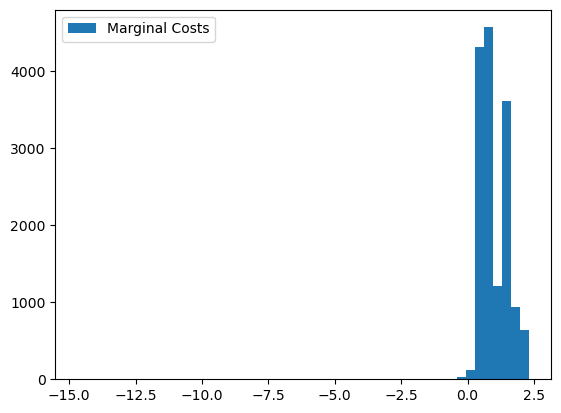

In [21]:
costs = results.compute_costs()
plt.hist(costs, bins=50);
plt.legend(["Marginal Costs"]);
plt.savefig("./marginalcost_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

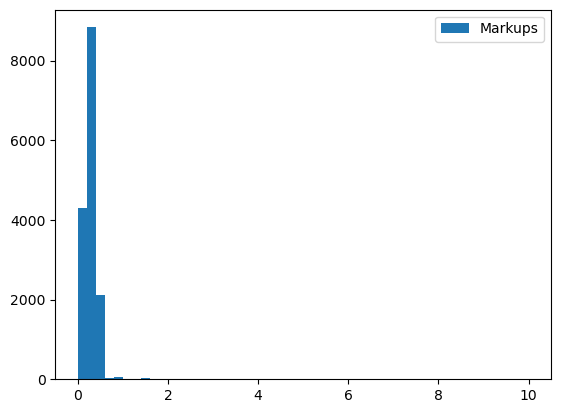

In [22]:
markups = results.compute_markups(costs=costs)
plt.hist(markups, bins=50, range=(0,10));
plt.legend(["Markups"]);
plt.savefig("./markups_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

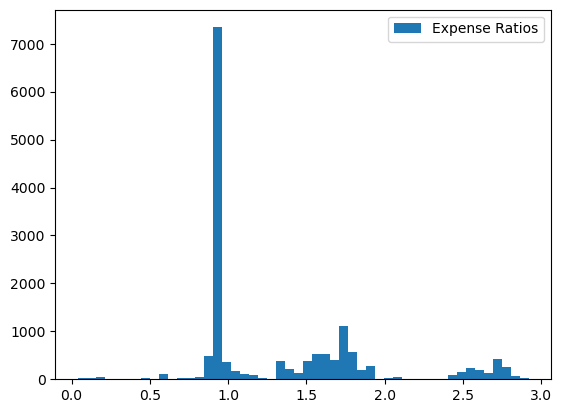

In [23]:
prices = product_data["prices"]
plt.hist(prices, bins=50);
plt.legend(["Expense Ratios"]);
plt.savefig("./expenseratio_hist.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [24]:
# For BLP with more RCs, we need more instruments
product_data = product_data.rename(columns={
    'BLP_IV_rival_funds4': 'demand_instruments2'
})

product_data = product_data.rename(columns={
    'BLP_IV_newproduct_1': 'demand_instruments3'
})

In [ ]:
# Prepare BLP with additional RCs V2
X1_formulation = pyblp.Formulation('0 + prices + product_tracking_err + product_past_1yr_ret + log_product_fund_age', absorb='C(product_ids) + C(market_ids)')  
X2_formulation = pyblp.Formulation('0 + prices + log_product_fund_age + product_past_1yr_ret')
product_formulations = (X1_formulation, X2_formulation)
product_formulations

mc_integration = pyblp.Integration('monte_carlo', size=3000, specification_options={'seed': 623543})
mc_integration

mc_problem = pyblp.Problem(product_formulations, product_data, integration=mc_integration)
mc_problem

bfgs = pyblp.Optimization('bfgs', {'gtol': 1e-7})
bfgs

# Solve BLP
results_v3 = mc_problem.solve(np.identity(3), optimization=bfgs, se_type='clustered')
results_v3

In [ ]:
# compute elasticities, diversion ratio, costs, and markups for RC v3
elasticities = results_v3.compute_elasticities()
diversions = results_v3.compute_diversion_ratios()
costs = results_v3.compute_costs()
markups = results_v3.compute_markups(costs=costs)

means = results_v3.extract_diagonal_means(elasticities)
aggregates = results_v3.compute_aggregate_elasticities(factor=0.1)

mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()
mean_own

In [ ]:
# Elasticities of the other variables
print(results_v3.extract_diagonal_means(results_v3.compute_elasticities(name='product_tracking_err')).flatten().mean())
print(results_v3.extract_diagonal_means(results_v3.compute_elasticities(name='product_past_1yr_ret')).flatten().mean())
print(results_v3.extract_diagonal_means(results_v3.compute_elasticities(name='log_product_fund_age')).flatten().mean())

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Keep your mean calculations
mean_own = means.flatten().mean()
mean_agg = aggregates.flatten().mean()

# Set the figure size if needed
plt.figure(figsize=(10*0.75, 6*0.75))

# Plot the density (KDE)
sns.kdeplot(means.flatten(), color='red', fill=True, label=f"Own Elasticities (Mean = {mean_own:.3f})")
sns.kdeplot(aggregates.flatten(), color='blue', fill=True, label=f"Aggregate Elasticities (Mean = {mean_agg:.3f})")

# Formatting
plt.legend()
plt.xlabel("Elasticity")
plt.ylabel("Density")
plt.title("Density Plot of Leveraged Fund BLP Elasticities")

# Save and show
plt.savefig("./BLP_elasticities_density_LETF.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
# compute elasticities, diversion ratio
results_v3.compute_elasticities()

In [ ]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = logit_results.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"logit_elasticities_lev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

In [ ]:
import os
import pandas as pd
import numpy as np

# suppose your data frame is called df
# and it contains a column named 'market_id'
market_ids = product_data['market_ids'].dropna().unique()

# optional: sort them
market_ids = sorted(market_ids)

# folder to save outputs
output_dir = "elasticity_outputs"
os.makedirs(output_dir, exist_ok=True)

for mid in market_ids:
    try:
        # compute elasticities for this market
        elast = results_v3.compute_elasticities(market_id=mid)

        # convert to DataFrame
        elast_df = pd.DataFrame(elast)

        # save to csv
        out_file = os.path.join(output_dir, f"elasticities_lev_market_{mid}.csv")
        elast_df.to_csv(out_file, index=False)

        print(f"Saved: {out_file}")

    except Exception as e:
        print(f"Error for market_id={mid}: {e}")

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.25 if {f, g} == {"ProShares", "Direxion"}
        else 0.25 if {f, g} == {"ProFunds", "Direxion"}
       else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.5 if {f, g} == {"ProShares", "Direxion"}
        else 0.5 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.55 if {f, g} == {"ProShares", "Direxion"}
        else 0.55 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.6 if {f, g} == {"ProShares", "Direxion"}
        else 0.6 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.7 if {f, g} == {"ProShares", "Direxion"}
        else 0.7 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.75 if {f, g} == {"ProShares", "Direxion"}
        else 0.75 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

In [ ]:
testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Save the level markup, level marginal cost, and lerner index data into the df
product_data['BLP_mu_pc'] = testing_results.markups[0]
product_data['BLP_mu_bt'] = testing_results.markups[1]
product_data['BLP_mu_bt_prosh_direx_025'] = testing_results.markups[2]
product_data['BLP_mu_bt_prosh_direx_050'] = testing_results.markups[3]
product_data['BLP_mu_bt_prosh_direx_055'] = testing_results.markups[4]
product_data['BLP_mu_bt_prosh_direx_060'] = testing_results.markups[5]
product_data['BLP_mu_bt_prosh_direx_065'] = testing_results.markups[6]
product_data['BLP_mu_bt_prosh_direx_070'] = testing_results.markups[7]
product_data['BLP_mu_bt_prosh_direx_075'] = testing_results.markups[8]
product_data['BLP_mu_cournot'] = testing_results.markups[9]
product_data['BLP_mu_monopoly'] = testing_results.markups[10]

product_data['BLP_mc_pc'] = testing_results.marginal_cost[0]
product_data['BLP_mc_bt'] = testing_results.marginal_cost[1]
product_data['BLP_mc_bt_prosh_direx_025'] = testing_results.marginal_cost[2]
product_data['BLP_mc_bt_prosh_direx_050'] = testing_results.marginal_cost[3]
product_data['BLP_mc_bt_prosh_direx_055'] = testing_results.marginal_cost[4]
product_data['BLP_mc_bt_prosh_direx_060'] = testing_results.marginal_cost[5]
product_data['BLP_mc_bt_prosh_direx_065'] = testing_results.marginal_cost[6]
product_data['BLP_mc_bt_prosh_direx_070'] = testing_results.marginal_cost[7]
product_data['BLP_mc_bt_prosh_direx_075'] = testing_results.marginal_cost[8]
product_data['BLP_mc_cournot'] = testing_results.marginal_cost[9]
product_data['BLP_mc_monopoly'] = testing_results.marginal_cost[10]

product_data['BLP_lerner_pc'] = product_data['BLP_mu_pc']/product_data['prices']
product_data['BLP_lerner_bt'] = product_data['BLP_mu_bt']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_025'] = product_data['BLP_mu_bt_prosh_direx_025']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_050'] = product_data['BLP_mu_bt_prosh_direx_050']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_055'] = product_data['BLP_mu_bt_prosh_direx_055']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_060'] = product_data['BLP_mu_bt_prosh_direx_060']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_065'] = product_data['BLP_mu_bt_prosh_direx_065']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_070'] = product_data['BLP_mu_bt_prosh_direx_070']/product_data['prices']
product_data['BLP_lerner_bt_prosh_direx_075'] = product_data['BLP_mu_bt_prosh_direx_075']/product_data['prices']
product_data['BLP_lerner_cournot'] = product_data['BLP_mu_cournot']/product_data['prices']
product_data['BLP_lerner_monopoly'] = product_data['BLP_mu_monopoly']/product_data['prices']

print(np.mean(product_data['BLP_lerner_pc']>1))
print(np.mean(product_data['BLP_lerner_bt']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_025']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_050']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_055']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_060']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_065']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_070']>1))
print(np.mean(product_data['BLP_lerner_bt_prosh_direx_075']>1))
print(np.mean(product_data['BLP_lerner_cournot']>1))
print(np.mean(product_data['BLP_lerner_monopoly']>1))


In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[2].ravel(), label='Bertrand (0.25 Profit Weights: ProShares+Direxion)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[3].ravel(), label='Bertrand (0.50 Profit Weights: ProShares+Direxion)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[8].ravel(), label='Bertrand (0.75 Profit Weights: ProShares+Direxion)', color='green', fill=True, alpha=0.25)

plt.xlim(0, 2)
plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

#plt.savefig("./Bertrand and Partial Collusion Combos.pdf", format="pdf", bbox_inches="tight")
#plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand (Baseline)', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_prosh_direx_025'], label='Bertrand (0.25 Profit Weights: ProShares+Direxion)', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_prosh_direx_050'], label='Bertrand (0.50 Profit Weights: ProShares+Direxion)', color='yellow', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_bt_prosh_direx_075'], label='Bertrand (0.75 Profit Weights: ProShares+Direxion)', color='green', fill=True, alpha=0.25)

plt.xlim(0, 2)
plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Lerner Bertrand and Partial Collusion.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_lerner_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_lerner_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-1, 5)
plt.ylim(0, 6)
plt.xlabel('Lerner Index (Markup divided by Price)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Lerner Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=product_data['BLP_mc_bt'], label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_cournot'], label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=product_data['BLP_mc_monopoly'], label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(-6, 4)
plt.ylim(0, 2)
plt.xlabel('Marginal Costs implied by Conduct (percentage points per annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./MC Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
import seaborn as sns

plt.figure(figsize=(8, 6)) # Optional: control figure size

# Plot the first density curve
sns.kdeplot(x=testing_results.markups[1].ravel(), label='Bertrand', color='blue', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[9].ravel(), label='Cournot', color='red', fill=True, alpha=0.25)
sns.kdeplot(x=testing_results.markups[10].ravel(), label='Monopoly', color='green', fill=True, alpha=0.25)

plt.xlim(0, 5)
plt.ylim(0, 6)
plt.xlabel('Markup (Price minus Marginal Cost in Percentage Points per Annum)')
plt.ylabel('Density')
plt.legend() # Show the legend with the labels

plt.savefig("./Cournot_Monopoly.pdf", format="pdf", bbox_inches="tight")
plt.show()

In [ ]:
# Save implied marginal costs
product_data.to_csv("lev_product_data_w_costs_Mar2025.csv", index=False)
# product_data.to_csv("lev_product_data_w_costs_Mar2025_BLPRC1.csv", index=False)

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.25 if {f, g} == {"ProShares", "Direxion"}
        else 0.25 if {f, g} == {"ProFunds", "Direxion"}
       else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.5 if {f, g} == {"ProShares", "Direxion"}
        else 0.5 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.55 if {f, g} == {"ProShares", "Direxion"}
        else 0.55 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.6 if {f, g} == {"ProShares", "Direxion"}
        else 0.6 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.7 if {f, g} == {"ProShares", "Direxion"}
        else 0.7 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.75 if {f, g} == {"ProShares", "Direxion"}
        else 0.75 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age3
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income3_resid
# This works: BLP_IV_rival_funds3*Conduct_IV_csent_index_resid

### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Robustness to alternative IVs

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.040)*np.log(product_data_econ_scale['product_mtna'])
#product_data_econ_scale['index_product_mtna'] = product_data_econ_scale.groupby('market_m_index')['product_mtna'].transform('sum')
#product_data_econ_scale['prices'] = product_data_econ_scale['prices'] - (-0.116)*np.log(product_data_econ_scale['index_product_mtna'])

#product_data_econ_scale['log_product_mtna'] = np.log(product_data_econ_scale['product_mtna'])

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (
        # Neg works better than abs as we expect
        #pyRVtest.Formulation('0 + Conduct_IV_abs_vw_ind_resid_1m + Conduct_IV_abs_vw_ind_resid_2to5m + Conduct_IV_abs_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + Conduct_IV_neg_vw_ind_resid_1m + Conduct_IV_neg_vw_ind_resid_2to5m + Conduct_IV_neg_vw_ind_resid_6to12m')
        #pyRVtest.Formulation('0 + demand_instruments0 + IV_x_neg_vw_ind_resid_1m + IV_x_neg_vw_ind_resid_2to5m + IV_x_neg_vw_ind_resid_6to12m')        
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      

### These interactions reject PC and support ProShares + Direxion
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_index_resid
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_income1_resid (Strongest), Conduct_IV_csent_income2_resid, Conduct_IV_csent_income3_resid (Weakest)
# This works: BLP_IV_rival_funds2*Conduct_IV_csent_age1, Conduct_IV_csent_age2, Conduct_IV_csent_age3 (All about the same)
# This works: BLP_IV_rival_funds2*rotator
# rotator by itself is similar directions but insignificant
# Conduct_IV_csent_index_resid by itself is insignificant
# BLP_IV_rival_funds2 by itself is similar directions but insignificant
# BLP_IV_rival_funds3 by itself is perfect competition/ most interactions with BLP_IV_rival_funds3 have PC == PW

# Results are stronger if only the interaction is in the IV and the standalone terms are put into the cost formulation


### These interactions reject PC and support ProShares + ProFunds
# This works: BLP_IV_rival_funds2*Conduct_IV_vol_resid1

        #  List of candidate instruments
#  77  Conduct_IV_gs_leveraged_etf_resid           26937 non-null  float64
#  78  Conduct_IV_gs_bitcoin_resid        26937 non-null  float64
#  79  Conduct_IV_csent_index_resid       26937 non-null  float64
#  80  Conduct_IV_vol_resid1           26937 non-null  float64
#  80  BLP_IV_waldfan_exp_ratio           26937 non-null  float64

    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification4),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification5),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification7),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification8),
        #pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification10)
        #pyRVtest.ModelFormulation(model_downstream='cournot', ownership_downstream='firm_ids'),
        #pyRVtest.ModelFormulation(model_downstream='monopoly', ownership_downstream='firm_ids')
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
import copy

def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0
    )

def kappa_specification2(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.25 if {f, g} == {"ProShares", "Direxion"}
        else 0.25 if {f, g} == {"ProFunds", "Direxion"}
       else 0
    )

def kappa_specification3(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.5 if {f, g} == {"ProShares", "Direxion"}
        else 0.5 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification4(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.55 if {f, g} == {"ProShares", "Direxion"}
        else 0.55 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification5(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.6 if {f, g} == {"ProShares", "Direxion"}
        else 0.6 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification6(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )
  
def kappa_specification7(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.7 if {f, g} == {"ProShares", "Direxion"}
        else 0.7 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

def kappa_specification8(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.75 if {f, g} == {"ProShares", "Direxion"}
        else 0.75 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

In [ ]:
# Counterfactual based on holding marginal costs fixed, and then changing the ownership matrix

# Version where we adjust the price to account for economies of scale:
product_data_econ_scale=copy.deepcopy(product_data)

# Now set up problem for conduct testing
testing_problem = pyRVtest.Problem(
    cost_formulation = (
        pyRVtest.Formulation('0 + log_product_fund_age + product_tracking_err + product_past_1yr_ret', absorb = 'C(product_ids) + C(market_ids)' )
    ),
    instrument_formulation = (   
        pyRVtest.Formulation('0 + BLP_IV_rival_funds2*Conduct_IV_csent_index_resid')      
    ),
    model_formulations = (
        pyRVtest.ModelFormulation(model_downstream='perfect_competition', ownership_downstream='firm_ids'),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification1),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification2),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification3),
        pyRVtest.ModelFormulation(model_downstream='bertrand', ownership_downstream='firm_ids', kappa_specification_downstream=kappa_specification6),
    ),
    product_data = product_data_econ_scale,
    demand_results = results_v3
)
testing_problem

testing_results = testing_problem.solve(
    demand_adjustment=False,    
    clustering_adjustment=True
)
testing_results

In [ ]:
# Check the pyRVTest and pyBLP have same baseline
def kappa_specification1(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0.65 if {f, g} == {"ProShares", "Direxion"}
        else 0.65 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

costs_baseline = results_v3.compute_costs(
            ownership=pyblp.build_ownership(product_data, kappa_specification1)
)

print(costs_baseline.flatten().mean())
print(testing_results.marginal_cost[4].flatten().mean())

# Try a different numerical method without changing the economics.
iteration = pyblp.Iteration(
    "hybr"
)

prices_baseline = results_v3.compute_prices(
            ownership=pyblp.build_ownership(product_data, kappa_specification1),
            costs=costs_baseline,
            constant_costs=True,
            iteration=iteration
        )

print(prices_baseline.flatten().mean())

In [ ]:
############### Baseline for the selected conduct model and economies of scale ########################
markups_baseline = results_v3.compute_markups(
    prices=prices_baseline,
    costs=costs_baseline
)

#costs_baseline = costs_baseline + (-0.040)*np.log(np.asarray(product_data_econ_scale['product_mtna'])).reshape(-1,1)
#prices_baseline = prices_baseline + (-0.040)*np.log(np.asarray(product_data_econ_scale['product_mtna'])).reshape(-1,1)

print(costs_baseline.flatten().mean())
print(markups_baseline.flatten().mean()) ### Markups in pyBLP is normalized
print(prices_baseline.flatten().mean())
print(prices_baseline.flatten().mean()-costs_baseline.flatten().mean()) ### Markups in RVTest is level

shares_baseline = results_v3.compute_shares(
    prices=prices_baseline
)

profits_baseline = results_v3.compute_profits(
    prices=prices_baseline,
    costs=costs_baseline,
    shares=shares_baseline
)

surplus_baseline = results_v3.compute_consumer_surpluses(
    prices=prices_baseline
)

print(shares_baseline.flatten().mean())
print(profits_baseline.flatten().mean())
print(surplus_baseline.flatten().mean())


In [ ]:
passthrough_baseline = results_v3.compute_passthrough(ownership=pyblp.build_ownership(product_data, kappa_specification1))
passthrough_baseline

In [ ]:
print(np.quantile(costs_baseline, [0, 0.01, 0.50, 0.99, 1]))
print("Fraction of baseline costs below zero:", np.mean(costs_baseline < 0))


In [ ]:
############### Counterfactual holding marginal costs and demand primitives fixed and changing conduct to bertrand ########################
def kappa_specification_alt(f, g):
    return (
        1 if f == g
        else 1 if {f, g} == {"ProShares", "ProFunds"}
        else 0 if {f, g} == {"ProShares", "Direxion"}
        else 0 if {f, g} == {"ProFunds", "Direxion"}
        else 0
    )

# Try a different numerical method without changing the economics.
iteration = pyblp.Iteration(
    "hybr"
)

prices_bertrand = results_v3.compute_prices(
            ownership=pyblp.build_ownership(product_data, kappa_specification_alt),
            costs=costs_baseline,
            constant_costs=True,
            iteration=iteration
        )

markups_bertrand = results_v3.compute_markups(
    prices=prices_bertrand,
    costs=costs_baseline
)

print(costs_baseline.flatten().mean())
print(markups_bertrand.flatten().mean())
print(prices_bertrand.flatten().mean())

shares_bertrand = results_v3.compute_shares(
prices=prices_bertrand
)

profits_bertrand = results_v3.compute_profits(
prices=prices_bertrand,
    costs=costs_baseline,
shares=shares_bertrand
)

surplus_bertrand = results_v3.compute_consumer_surpluses(
prices=prices_bertrand
)

print(shares_bertrand.flatten().mean())
print(profits_bertrand.flatten().mean())
print(surplus_bertrand.flatten().mean())


In [ ]:
############### Counterfactual holding marginal costs and demand primitives fixed and changing conduct to perfect competition ########################
prices_pc = costs_baseline

print(costs_pc.flatten().mean())
print(prices_pc.flatten().mean())

shares_pc = results_v3.compute_shares(
prices=prices_pc
)

profits_pc = results_v3.compute_profits(
prices=prices_pc,
    costs=costs_baseline,
shares=shares_pc
)

surplus_pc = results_v3.compute_consumer_surpluses(
prices=prices_pc
)

print(shares_pc.flatten().mean())
print(profits_pc.flatten().mean())
print(surplus_pc.flatten().mean())



In [ ]:
############### Counterfactual holding marginal costs and demand primitives fixed and changing economies of scale to 0 ########################
costs_noscale = costs_baseline - (-0.040)*np.log(np.asarray(product_data_econ_scale['product_mtna'])).reshape(-1,1)

prices_noscale = results_v3.compute_prices(
            ownership=pyblp.build_ownership(product_data, kappa_specification1),
            costs=costs_noscale,
            constant_costs=True,
            iteration=iteration
        )

markups_noscale = results_v3.compute_markups(
    prices=prices_noscale,
    costs=costs_baseline
)

print(costs_noscale.flatten().mean())
print(markups_noscale.flatten().mean())
print(prices_noscale.flatten().mean())

shares_noscale = results_v3.compute_shares(
prices=prices_noscale
)

profits_noscale = results_v3.compute_profits(
prices=prices_noscale,
    costs=costs_noscale,
shares=shares_noscale
)

surplus_noscale = results_v3.compute_consumer_surpluses(
prices=prices_noscale
)

print(shares_noscale.flatten().mean())
print(profits_noscale.flatten().mean())
print(surplus_noscale.flatten().mean())



In [ ]:
# Sanity check of pass through
print(costs_baseline.flatten().mean()-costs_noscale.flatten().mean())

print(prices_baseline.flatten().mean()-prices_noscale.flatten().mean())


In [ ]:
############### Counterfactual holding marginal costs and demand primitives fixed and changing economies of scale to 0 and changing economies of scale of perfect competition ########################
costs_noscale_pc = costs_baseline - (-0.040)*np.log(np.asarray(product_data_econ_scale['product_mtna'])).reshape(-1,1)

prices_noscale_pc = costs_noscale_pc

print(costs_noscale_pc.flatten().mean())
print(prices_noscale_pc.flatten().mean())

shares_noscale_pc = results_v3.compute_shares(
prices=prices_noscale_pc
)

profits_noscale_pc = results_v3.compute_profits(
prices=prices_noscale_pc,
    costs=costs_noscale_pc,
shares=shares_noscale_pc
)

surplus_noscale_pc = results_v3.compute_consumer_surpluses(
prices=prices_noscale_pc
)

print(shares_noscale_pc.flatten().mean())
print(profits_noscale_pc.flatten().mean())
print(surplus_noscale_pc.flatten().mean())



In [ ]:
# Save counterfactuals
product_data['cf_costs_baseline'] = costs_baseline.reshape(-1,1)
product_data['cf_prices_baseline'] = prices_baseline.reshape(-1,1)
product_data['cf_shares_baseline'] = shares_baseline.reshape(-1,1)

product_data['cf_costs_bertrand'] = costs_baseline.reshape(-1,1)
product_data['cf_prices_bertrand'] = prices_bertrand.reshape(-1,1)
product_data['cf_shares_bertrand'] = shares_bertrand.reshape(-1,1)

product_data['cf_costs_pc'] = costs_baseline.reshape(-1,1)
product_data['cf_prices_pc'] = prices_pc.reshape(-1,1)
product_data['cf_shares_pc'] = shares_pc.reshape(-1,1)

product_data['cf_costs_noscale'] = costs_noscale.reshape(-1,1)
product_data['cf_prices_noscale'] = prices_noscale.reshape(-1,1)
product_data['cf_shares_noscale'] = shares_noscale.reshape(-1,1)

product_data['cf_costs_noscale_pc'] = costs_noscale_pc.reshape(-1,1)
product_data['cf_prices_noscale_pc'] = prices_noscale_pc.reshape(-1,1)
product_data['cf_shares_noscale_pc'] = shares_noscale_pc.reshape(-1,1)

# Save implied marginal costs
product_data.to_csv("lev_product_data_w_costs_Oct2026_counterfactual.csv", index=False)
